## Imports

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

from sklearn.model_selection import train_test_split, cross_validate, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import ConfusionMatrixDisplay

## 1. Loading and visualization of data

In [2]:
df = pd.read_csv('telcom_customer_dataset.csv')
print(df.shape)
display(df.isna().sum().sort_values(ascending=False))

(7043, 21)


customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

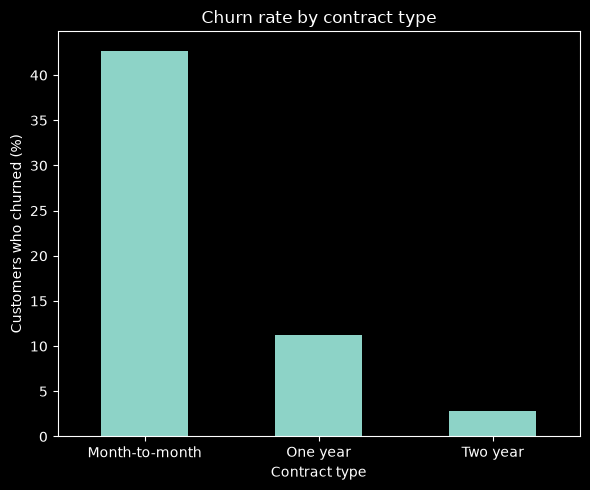

In [3]:
churn_rate = (
    df.groupby("Contract")["Churn"]
    .apply(lambda s: (s == "Yes").mean() * 100)
)

churn_rate.plot(kind="bar", rot=0, figsize=(6, 5))
plt.title("Churn rate by contract type")
plt.ylabel("Customers who churned (%)")
plt.xlabel("Contract type")
plt.tight_layout()
plt.show()

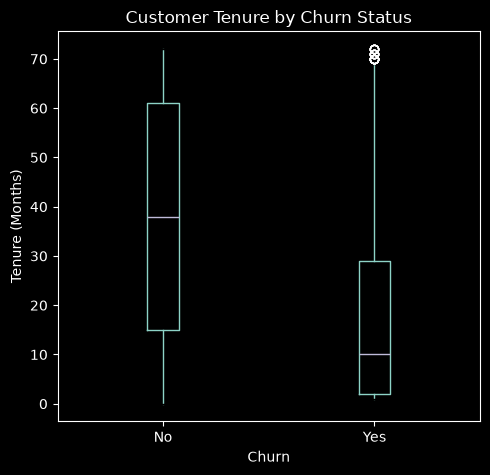

In [4]:
df.boxplot(
    column="tenure",
    by="Churn",
    figsize=(5, 5),
    grid=False
)

plt.title("Customer Tenure by Churn Status")
plt.suptitle("")
plt.xlabel("Churn")
plt.ylabel("Tenure (Months)")
plt.tight_layout()
plt.show()

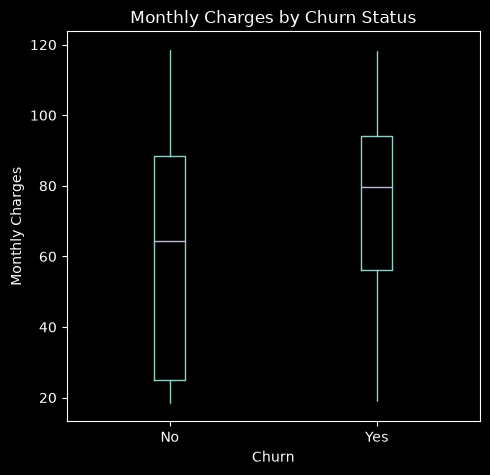

In [5]:
df.boxplot(
    column="MonthlyCharges",
    by="Churn",
    figsize=(5, 5),
    grid=False
)

plt.title("Monthly Charges by Churn Status")
plt.suptitle("")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")
plt.tight_layout()
plt.show()

From the first plot we can assume that contract type highly affects the propability of churn, if the contract is longer there is less propability of customer to leave. Second plot shows that customers with longer tenure are willing to stay with company when the ones that are not there for that long have higher propability to leave. Last plot shows that people that pay more monthly have more propability to leave.

## 2. Data Preprocessing

In [6]:
print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isna().sum().sort_values(ascending=False).head(10))


Data types:
customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object

Missing values:
customerID         0
gender             0
SeniorCitizen      0
Partner            0
Dependents         0
tenure             0
PhoneService       0
MultipleLines      0
InternetService    0
OnlineSecurity     0
dtype: int64


In [7]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"].replace(r"^\s*$", np.nan, regex=True),
    errors="coerce"
)

print("Missing TotalCharges:", df["TotalCharges"].isna().sum())
print("TotalCharges type:", df["TotalCharges"].dtype)

Missing TotalCharges: 11
TotalCharges type: float64


In [8]:
df = df.dropna(subset=["Churn"]).copy()

y = df["Churn"].map({"No": 0, "Yes": 1})

X = df.drop(columns=["Churn", "customerID"])

print("Features shape:", X.shape)
print("Target shape:", y.shape)

display(y.value_counts().rename(index={0: "No churn", 1: "Churn"}))

Features shape: (7043, 19)
Target shape: (7043,)


Churn
No churn    5174
Churn       1869
Name: count, dtype: int64

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [10]:
print("Shape of X training", X_train.shape)
print("Shape of X testing:", X_test.shape)

Shape of X training (5634, 19)
Shape of X testing: (1409, 19)


In [11]:
numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    exclude=["number"]
).columns.tolist()

In [12]:
print('Numeric columns: ',numeric_features)
print('Categorical columns: ',categorical_features)

Numeric columns:  ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical columns:  ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [13]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

In [14]:
logistic_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])


logistic_pipeline.fit(X_train, y_train)
print('Logistic Regression model has been trained')

Logistic Regression model has been trained


In this section the dataset was prepared for training. We have converted column 'TotalCharges' from string to numeric format and removed customerID column, because it was not necessary in the dataset.The data was split into two sets train and test (80 to 20). Numerical and categorical features were then assigned separate preprocessing pipelines. Missing values are handled with a usage of median from the rest of numerical features, and missing values in categorical features has been handled with the most-frequent.Numerical features are standardized, while categorical variables are encoded using One-Hot Encoding. imputation

## 3. Model training

In [24]:
random_forest_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        max_depth=None,
        min_samples_split=2,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    ))
])

random_forest_pipeline.fit(X_train, y_train)
print('Random forest model has been trained')


Random forest model has been trained


In [25]:
y_pred_logistic = logistic_pipeline.predict(X_test)

y_prob_logistic = logistic_pipeline.predict_proba(X_test)[:, 1] #propability of churn

In [17]:
print("First 10 predictions: ", y_pred_logistic[:10])

print("First 10 churn probabilities: ", y_prob_logistic[:10].round(3))

First 10 predictions:  [0 1 0 1 0 1 1 0 0 1]
First 10 churn probabilities:  [0.115 0.853 0.147 0.661 0.06  0.806 0.698 0.294 0.009 0.653]


In [18]:
y_pred_rf = random_forest_pipeline.predict(X_test)

y_prob_rf = random_forest_pipeline.predict_proba(X_test)[:, 1]
print("First 10 predictions:", y_pred_rf[:10])
print("First 10 churn probabilities:", y_prob_rf[:10].round(3))

First 10 predictions: [0 1 0 1 0 1 1 0 0 1]
First 10 churn probabilities: [0.024 0.818 0.094 0.542 0.05  0.76  0.601 0.176 0.008 0.612]


In [19]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}
models = {
    "Logistic Regression": logistic_pipeline,
    "Random Forest": random_forest_pipeline
}

In [20]:
cv_results = []
for name, model in models.items():
    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    cv_results.append({
        "Model": name,
        "Accuracy": scores["test_accuracy"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1-score": scores["test_f1"].mean(),
        "ROC-AUC": scores["test_roc_auc"].mean()
    })

cv_results_df = pd.DataFrame(cv_results)
display(cv_results_df.round(3))


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,0.748,0.516,0.801,0.628,0.846
1,Random Forest,0.764,0.540,0.759,0.631,0.845


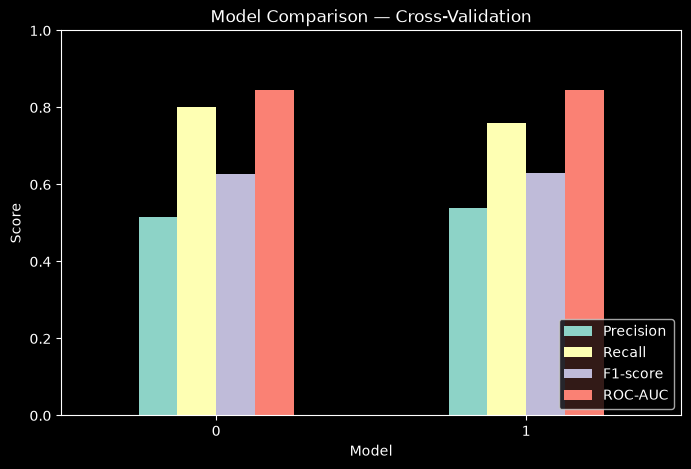

In [21]:
(cv_results_df[
    ["Precision", "Recall", "F1-score", "ROC-AUC"]].plot
    (
    kind="bar",
    figsize=(8, 5)
))

plt.title("Model Comparison — Cross-Validation")
plt.xlabel("Model")
plt.ylabel("Score")
plt.ylim(0,1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.show()

In [22]:
logistic_pipeline.fit(X_train, y_train)
random_forest_pipeline.fit(X_train, y_train)

print("Both models have been refitted")

Both models have been refitted


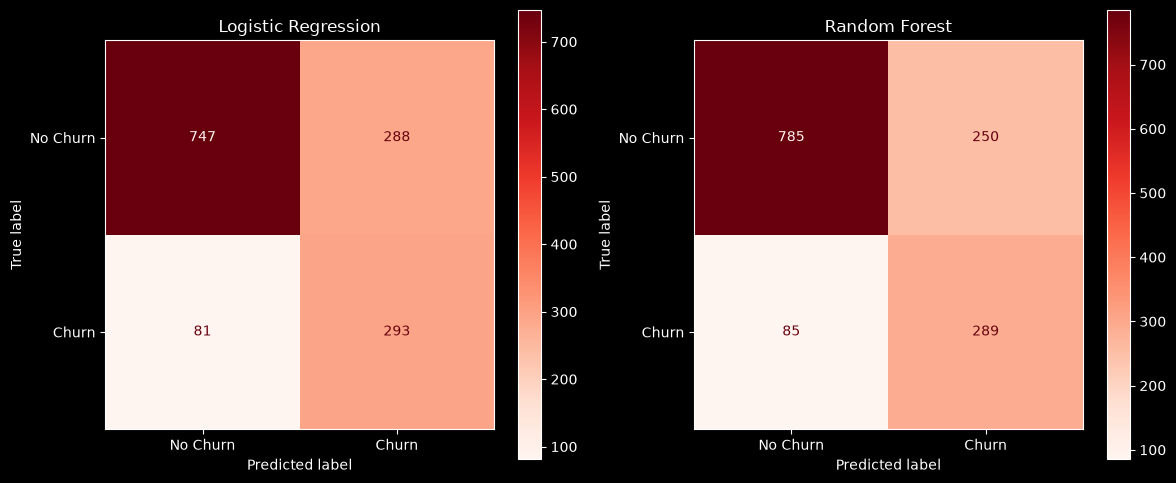

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_logistic,
    display_labels=["No Churn", "Churn"],
    ax=axes[0],
    colorbar=True,
    cmap="Reds"
)
axes[0].set_title("Logistic Regression")

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_rf,
    display_labels=["No Churn", "Churn"],
    ax=axes[1],
    colorbar=True,
    cmap="Reds"
)
axes[1].set_title("Random Forest")

plt.tight_layout()
plt.show()

We have trained two classification models: Logistic Regression and Random Forest. Both models use Pipeline thath combines preprocessing with model training. This ensures that transformations are fitted on the training data and applied consistently during prediction. Stratified five-fold cross-validation was used to compare model performance using accuracy, precision, recall, F1-score, and ROC-AUC. Cross-validation allows us to have a wider peak on the models


### Model Evaluation

Logistic Regression performed better in terms of Recall (0.801) and ROC-AUC (0.846), while Random Forest achieved higher Accuracy (0.776) and Precision (0.568)

Recall: Logistic Regression achieved a Recall of 0.801 while Random Forest 0.645 meaning Logistic Regression corectly identified about 15% more customers who actually churned

Precision: Logistic Regression achieved a Precision of 0.516,Random Forest achieved a higher Precision of 0.568, resulting in a lower proportion of false positive predictions among customers flagged as likely to churn.

Model comparison: Logistic Regression achieved an F1-score of 0.628 and a ROC-AUC of 0.846, compared with 0.604 and 0.822 for Random Forest. Overall, Logistic Regression provided a better balance between churn detection and classification performance.
